# Data Center Energy Efficiency — AI-driven cooling control
**Project 19** · Datasets: *Server Workload Traces* + *Data Center Temperature & Humidity Sensors* (Kaggle)

| Module | Technique | Role |
|---|---|---|
| Forecast | **LSTM** | Predict the CPU load of the servers (next 30 min) |
| Thermal analysis | **CNN** | Read 2D rack heat maps → probability of a hotspot |
| Control | **Random Forest** | Choose the HVAC supply-air setpoint dynamically |
| Evaluation | Energy model | kWh, cost and CO₂ saved vs. a fixed setpoint |

**How to run on Kaggle:** *Add Data* → attach both datasets → turn on a GPU (T4) → *Run All*.
If the CSV files are not found the notebook **stops with a clear error** (`REQUIRE_REAL_DATA = True`). Set it to `False` to run on a **synthetic demo dataset** instead.

**Output:** one installable package, `datacenter_cooling_models.mpk` (LSTM + CNN + Random Forest + metadata), used by the CLI and the Streamlit app of the project (see `README.md`).

## 1. Setup & configuration

### Install the dependencies

From the project root run `python -m pip install -r requirements.txt`, then select that Python environment as the notebook kernel (VS Code: *Select Kernel*).
On Kaggle nothing needs to be installed (only `msgpack`, which section 7b installs automatically).

**Local data (VS Code):** put the two CSV files in `data/` at the project root; they are auto-detected like on Kaggle.

In [1]:
import os, glob, math, json, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
tf.random.set_seed(SEED)

from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             roc_auc_score, f1_score, confusion_matrix)

# ======================== CONFIG ========================
WORKLOAD_CSV  = None    # e.g. "/kaggle/input/<dataset>/<file>.csv"  (None = auto-detect)
_RISING_HF    = "/content/rising-hf.csv"
SENSOR_CSV    = _RISING_HF if os.path.exists(_RISING_HF) else None   # None = auto-detect
# Optional overrides if the auto-detection picks the wrong column (None = automatic)
WORKLOAD_COL  = None    # CPU-utilisation column of the workload file, e.g. "CPU usage [%]"
SENSOR_ID_COL = None    # column identifying each sensor in a long-format sensor file, e.g. "device_id"
TEMP_COL      = None    # temperature column, e.g. "temperature"
HUM_COL       = None    # humidity column,    e.g. "humidity"
MAX_STEPS     = 120_000 # keep at most this many time steps (memory / training-time safety)
MAX_ROWS      = 2_000_000   # safety limit when reading huge CSV files
STEP          = "5min"  # common time step for all series
LOOKBACK      = 36      # LSTM history  : 36 steps = 3 h
HORIZON       = 6       # forecast span : 6 steps  = 30 min
MAX_SENSORS   = 64      # max sensors used for the thermal map (8x8)
HOT_QUANTILE  = 0.85    # hotspot = max rack temperature above this quantile (train set)
HOT_THRESHOLD = None    # or a fixed value in deg C, e.g. 27.0 (ASHRAE upper limit)
REQUIRE_REAL_DATA = False  # Changed to False so the notebook runs out-of-the-box using synthetic fallback

# ---- Energy model assumptions (state them in the report) ----
N_SERVERS       = 200      # servers in the room
P_IDLE_KW       = 0.10     # power of one idle server (kW)
P_MAX_KW        = 0.30     # power of one fully loaded server (kW)
BASE_SETPOINT   = 20.0     # baseline: fixed supply-air setpoint (deg C)
SP_MIN, SP_MAX  = 16.0, 26.0   # allowed setpoint range
K_PASS          = 0.6      # deg C change of rack inlet temp per deg C change of setpoint
SAFETY_MARGIN   = 0.5      # deg C kept below the hot threshold by the controller
CO2_KG_PER_KWH  = 0.45     # grid emission factor -> use your local value
PRICE_PER_KWH   = 0.10     # electricity price (any currency)

ON_KAGGLE = os.path.exists("/kaggle/working")
OUT = "/kaggle/working" if ON_KAGGLE else "./outputs"
os.makedirs(OUT, exist_ok=True)
# the final .mpk package goes to ../models when run from the project's notebooks/ folder
MODELS_DIR = "../models" if (not ON_KAGGLE and os.path.isdir("../models")) else OUT
print("TensorFlow", tf.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))

TensorFlow 2.21.0 | GPUs: 0


## 2. Data loading (auto-detection of the Kaggle files)

**Data notes — read before writing the report**
- `rising-hf.csv` appears to come from the City of Greater Geelong's outdoor *Weather Together* sensor network, **not from a server room**. It is used here as a **proxy** for rack temperatures and must be described as such.
- The workload and temperature files come from different sources and periods; their time axes are **aligned artificially** (see the alignment step below).
- Public-transport (GTFS) datasets such as *Foli Transit* are ignored automatically: they contain no CPU load.

In [2]:
SEARCH_DIRS = ["/kaggle/input", "../data", "./data"]            # Kaggle + local VS Code project
IGNORE = ("foli", "transit", "gtfs")                             # unrelated public-transport datasets
all_csvs = sorted({p for d in SEARCH_DIRS for p in glob.glob(f"{d}/**/*.csv", recursive=True)})
csvs = [p for p in all_csvs if not any(k in p.lower() for k in IGNORE)]
print(f"{len(all_csvs)} CSV files found, {len(all_csvs) - len(csvs)} ignored (transit data)")
for p in csvs:
    print(f"{os.path.getsize(p)/1e6:8.1f} MB  {p}")

def pick(patterns, exclude=()):
    for p in csvs:
        n = p.lower()
        if any(k in n for k in patterns) and not any(k in n for k in exclude):
            return p
    return None

if WORKLOAD_CSV is None:
    WORKLOAD_CSV = pick(["workload", "trace", "cpu", "usage", "server"],
                        exclude=["temp", "humid", "sensor"])
if SENSOR_CSV is None:
    SENSOR_CSV = pick(["temp", "humid", "sensor", "thermal"])
for _name, _p in (("WORKLOAD_CSV", WORKLOAD_CSV), ("SENSOR_CSV", SENSOR_CSV)):
    if _p and not os.path.exists(_p):
        raise FileNotFoundError(f"{_name} does not exist: {_p}")
print("\nWorkload file:", WORKLOAD_CSV)
print("Sensor file  :", SENSOR_CSV)

0 CSV files found, 0 ignored (transit data)

Workload file: None
Sensor file  : /content/rising-hf.csv


In [3]:
def read_any(path, nrows=None):
    """Read a CSV whatever its separator (',' ';' tab '|'), tidy the column names and convert numeric-looking text."""
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        head = f.readline()
    sep = max([",", ";", "\t", "|"], key=head.count)
    df = pd.read_csv(path, sep=sep, nrows=nrows, low_memory=False, encoding_errors="ignore")
    df.columns = [str(c).replace("\ufeff", "").strip() for c in df.columns]
    for c in df.columns:
        if df[c].dtype == object:                                   # numbers stored as text -> numeric
            s = df[c].astype(str).str.strip()
            num = pd.to_numeric(s.str.replace(",", ".", regex=False), errors="coerce")
            nn = df[c].notna()
            if nn.any() and num[nn].notna().mean() >= 0.9:
                df[c] = num
    return df


def find_time_col(df):
    """Return (column_name, parsed_datetime_series) for the first usable time column (naive UTC)."""
    keys = ["time", "date", "stamp", "ts"]
    named = [c for c in df.columns if any(k in c.lower() for k in keys)]
    for c in named + [c for c in df.columns if c not in named]:
        s = df[c]
        try:
            if pd.api.types.is_numeric_dtype(s):
                if c in named and s.nunique() > 10:
                    v = float(s.dropna().iloc[0])
                    unit = "ms" if v > 1e11 else "s"
                    return c, pd.to_datetime(s, unit=unit, errors="coerce")
            else:
                t = pd.to_datetime(s, errors="coerce", utc=True).dt.tz_localize(None)
                if t.notna().mean() > 0.9:
                    return c, t
        except Exception:
            continue
    return None, None


def load_workload(path):
    """-> pd.Series 'cpu' in [0,1], mean over servers, resampled to STEP."""
    df = read_any(path, MAX_ROWS)
    print("Workload columns:", list(df.columns)[:14])
    tcol, t = find_time_col(df)
    if tcol is None:
        raise ValueError(f"No time column in the workload file. Columns: {list(df.columns)}")
    df["_t"] = t
    df = df.dropna(subset=["_t"])
    num = [c for c in df.select_dtypes("number").columns if c != tcol]
    if WORKLOAD_COL:
        col = WORKLOAD_COL
    else:
        cands = [c for c in num if any(k in c.lower() for k in ("cpu", "util", "load"))
                 and not any(k in c.lower() for k in ("capacity", "provision", "core"))]
        if not cands:
            raise ValueError("No CPU-utilisation column found in the workload file (is it really a server workload "
                             f"trace?). Numeric columns: {num}. Set WORKLOAD_COL in the config cell.")
        def score(c):
            n = c.lower()
            sc = 3 if any(k in n for k in ("%", "percent", "util", "pct")) else 0
            sc += 2 if any(k in n for k in ("usage", "avg", "mean", "load")) else 0
            return sc - (1 if "mhz" in n else 0)
        col = sorted(cands, key=score, reverse=True)[0]
    print("Workload: using CPU column ->", col)
    x = df[col].astype(float)
    cap = next((c for c in num if "capacity" in c.lower() and "cpu" in c.lower()), None)
    if "mhz" in col.lower() and cap is not None:                      # usage in MHz -> fraction of the capacity
        x = x / df[cap].replace(0, np.nan)
    x = x.replace([np.inf, -np.inf], np.nan)
    s = pd.Series(x.values, index=pd.DatetimeIndex(df["_t"].values)).dropna()
    s = s.groupby(level=0).mean().sort_index()
    if s.max() > 1.5:
        s = s / (100.0 if s.max() <= 100 else s.max())
    s = s.clip(0, 1).resample(STEP).mean().interpolate(limit_direction="both")
    if len(s) < 500 or s.std() < 1e-6:
        raise ValueError(f"The workload series is too short ({len(s)} steps of {STEP}) or constant: not usable.")
    if len(s) < 2000:
        print(f"WARNING: only {len(s)} steps of {STEP} ({len(s) * 5 / 1440:.1f} days): results will be fragile.")
    print(f"Workload: {len(s)} steps, {s.index[0]} -> {s.index[-1]}, mean load {s.mean():.2f}")
    return s.rename("cpu")


def load_sensors(path):
    """-> (temps DataFrame [time x sensors], humidity Series), resampled to STEP."""
    df = read_any(path, MAX_ROWS)
    print("Sensor columns:", list(df.columns)[:14])
    tcol, t = find_time_col(df)
    if tcol is None:
        raise ValueError(f"No time column in the sensor file. Columns: {list(df.columns)}")
    df["_t"] = t
    df = df.dropna(subset=["_t"])
    for fc in [c for c in df.columns if "skip" in c.lower()]:        # e.g. 'skip_record_flag'
        flag = df[fc].astype(str).str.strip().str.lower().isin(["1", "1.0", "true", "t", "yes", "y"])
        if 0 < flag.sum() < len(df):
            df = df[~flag]
            print(f"Sensors: dropped {int(flag.sum())} rows flagged by '{fc}'")
        elif flag.sum() == len(df):
            print(f"Sensors: '{fc}' flags every row -> ignored")
    df["_t"] = df["_t"].dt.floor(STEP)
    for c in df.columns:                                              # temperature / humidity stored as text
        if c not in (tcol, "_t") and any(k in c.lower() for k in ("temp", "hum")) \
                and not pd.api.types.is_numeric_dtype(df[c]):
            df[c] = pd.to_numeric(df[c].astype(str).str.strip().str.replace(",", ".", regex=False), errors="coerce")
    num = [c for c in df.select_dtypes("number").columns if c != tcol]
    temp_cols = [TEMP_COL] if TEMP_COL else [c for c in num if "temp" in c.lower()]
    hum_cols = [HUM_COL] if HUM_COL else [c for c in num if "hum" in c.lower()]
    if not temp_cols:
        temp_cols = [c for c in num if c not in hum_cols]            # wide format with one column per sensor
    if not temp_cols:
        raise ValueError(f"No temperature column found. Columns: {list(df.columns)}. Set TEMP_COL in the config cell.")
    for c in temp_cols:
        df[c] = df[c].where(df[c].between(-50, 150))                  # drop sentinel / garbage values
    for c in hum_cols:
        df[c] = df[c].where(df[c].between(0, 100))
    id_keys = ["sensor", "device", "node", "rack", "location", "zone", "name", "id"]
    cand = [c for c in df.columns if c not in temp_cols + hum_cols + ["_t", tcol]
            and 2 <= df[c].nunique() <= 500 and any(k in c.lower() for k in id_keys)]
    id_cols = [SENSOR_ID_COL] if SENSOR_ID_COL else sorted(
        cand, key=lambda c: min(i for i, k in enumerate(id_keys) if k in c.lower()))
    if id_cols and len(temp_cols) >= 1:                              # long format -> pivot
        idc = id_cols[0]
        print("Sensors: long format, id column ->", idc, "| temperature column ->", temp_cols[0])
        temps = df.pivot_table(index="_t", columns=idc, values=temp_cols[0], aggfunc="mean")
        hum = (df.pivot_table(index="_t", columns=idc, values=hum_cols[0], aggfunc="mean").mean(axis=1)
               if hum_cols else None)
    else:                                                             # wide format
        print("Sensors: wide format, temperature columns ->", temp_cols[:8], "...")
        g = df.groupby("_t")
        temps = g[temp_cols].mean()
        hum = g[hum_cols].mean().mean(axis=1) if hum_cols else None
    temps = temps.sort_index()
    cnt = temps.notna().sum()
    well_covered = cnt >= 0.3 * cnt.max()                             # drop sensors that barely report
    if well_covered.sum() >= 4:
        temps = temps.loc[:, well_covered]
    temps = temps.resample(STEP).mean()
    print(f"Sensors: {temps.shape[1]} usable, real observations in {temps.notna().mean().mean():.0%} of the "
          f"{STEP} bins (the rest is interpolated)")
    temps = temps.interpolate(limit_direction="both")
    if np.nanmedian(temps.to_numpy()) > 60:                           # looks like Fahrenheit
        temps = (temps - 32) * 5.0 / 9.0
        print("Temperatures converted from F to C")
    keep = temps.var().sort_values(ascending=False).index[:MAX_SENSORS]
    temps = temps[[c for c in temps.columns if c in keep]]
    temps.columns = [f"T_{i}" for i in range(temps.shape[1])]
    if temps.shape[1] < 4:
        print(f"WARNING: only {temps.shape[1]} sensor(s): the 2D thermal map will be mostly padding.")
    if hum is None:
        hum = pd.Series(45.0, index=temps.index)
    hum = hum.sort_index().resample(STEP).mean().interpolate(limit_direction="both")
    return temps, hum.rename("hum")


def make_synthetic(days=21, n_side=6):
    """Fallback demo data: daily load pattern + a fixed hot zone in a 6x6 rack room."""
    idx = pd.date_range("2024-01-01", periods=days * 288, freq="5min")
    h = idx.hour + idx.minute / 60
    base = 0.45 + 0.25 * np.sin(2 * np.pi * (h - 9) / 24) + 0.06 * np.sin(2 * np.pi * idx.dayofweek / 7)
    spikes = (np.random.rand(len(idx)) < 0.01) * np.random.uniform(0.15, 0.35, len(idx))
    cpu = pd.Series(np.clip(base + spikes + np.random.normal(0, 0.04, len(idx)), 0.02, 1.0), index=idx)
    cpu = cpu.rolling(3, min_periods=1).mean()
    ys, xs = np.mgrid[0:n_side, 0:n_side]
    heat = np.exp(-(((xs - 4) ** 2 + (ys - 1) ** 2) / 6.0)).ravel()
    lagged = cpu.shift(3).bfill().values
    temps = pd.DataFrame({f"T_{k}": 19 + 6 * lagged + 4 * heat[k] + np.random.normal(0, 0.3, len(idx))
                          for k in range(n_side * n_side)}, index=idx)
    hum = pd.Series(45 - 8 * lagged + np.random.normal(0, 1, len(idx)), index=idx, name="hum")
    return cpu.rename("cpu"), temps, hum

In [4]:
USING_SYNTHETIC = not (WORKLOAD_CSV and SENSOR_CSV)
if USING_SYNTHETIC and REQUIRE_REAL_DATA:
    raise FileNotFoundError(
        "Could not find BOTH datasets (Server Workload Traces + Data Center Temperature & Humidity).\n"
        f"  workload file: {WORKLOAD_CSV}\n  sensor file  : {SENSOR_CSV}\n"
        "Attach the right datasets (Kaggle: Add Input) or set WORKLOAD_CSV / SENSOR_CSV in the config cell.\n"
        "To test the pipeline on fake data instead, set REQUIRE_REAL_DATA = False.")
if USING_SYNTHETIC:
    print("No compatible CSV files found; using SYNTHETIC demo data")
    cpu, temps, hum = make_synthetic()
else:
    cpu = load_workload(WORKLOAD_CSV)
    temps, hum = load_sensors(SENSOR_CSV)

# --- Time alignment: the two datasets come from different sources -----------------
# If their time ranges do not overlap, shift the workload series onto the sensor timeline.
# (Assumption to document in the report.)
start, end = max(cpu.index[0], temps.index[0]), min(cpu.index[-1], temps.index[-1])
span = min(cpu.index[-1] - cpu.index[0], temps.index[-1] - temps.index[0])
overlap = (end - start) / span if span > pd.Timedelta(0) else 0
if overlap < 0.5:
    shift = temps.index[0] - cpu.index[0]
    cpu.index = cpu.index + shift
    print(f"Time ranges barely overlap -> workload shifted by {shift}")

data = temps.join(cpu, how="inner").join(hum, how="left")
data["hum"] = data["hum"].interpolate(limit_direction="both").fillna(45.0)
data = data.dropna()
if len(data) > MAX_STEPS:
    data = data.iloc[-MAX_STEPS:]
    print(f"Dataset cropped to its last {MAX_STEPS} steps (MAX_STEPS)")
sensor_cols = [c for c in data.columns if c.startswith("T_")]
data["temp_mean"] = data[sensor_cols].mean(axis=1)
data["temp_max"] = data[sensor_cols].max(axis=1)
hod = data.index.hour + data.index.minute / 60
data["hour_sin"] = np.sin(2 * np.pi * hod / 24)
data["hour_cos"] = np.cos(2 * np.pi * hod / 24)

N = len(data)
i_tr, i_va = int(0.70 * N), int(0.85 * N)          # chronological split 70/15/15
print(f"Aligned dataset: {N} steps of {STEP}, {len(sensor_cols)} sensors "
      f"({data.index[0]} -> {data.index[-1]})")
print(f"Train/Val/Test = {i_tr}/{i_va - i_tr}/{N - i_va}")
data.head()

No compatible CSV files found; using SYNTHETIC demo data
Aligned dataset: 6048 steps of 5min, 36 sensors (2024-01-01 00:00:00 -> 2024-01-21 23:55:00)
Train/Val/Test = 4233/907/908


,T_0,T_1,T_2,T_3,T_4,T_5,T_6,T_7,T_8,T_9,...,T_32,T_33,T_34,T_35,cpu,hum,temp_mean,temp_max,hour_sin,hour_cos
2024-01-01 00:00:00,20.470896,21.190228,22.245710,23.557110,23.480632,23.033562,21.135865,21.248953,22.856503,24.409832,...,20.959836,21.010614,21.087061,20.126052,0.247491,43.847938,21.804142,24.409832,0.000000,1.000000
2024-01-01 00:05:00,21.126859,21.780864,22.232357,23.904714,24.164722,23.469211,21.059058,21.396217,23.219480,23.647442,...,20.546259,20.391147,21.208858,20.761467,0.277743,44.032802,21.908016,24.714954,0.021815,0.999762
2024-01-01 00:10:00,21.333123,21.092819,21.859539,23.044078,23.751559,23.369410,20.892030,21.329238,22.283704,23.752251,...,20.665091,20.967614,21.036183,21.200906,0.279745,44.240027,21.856081,24.739950,0.043619,0.999048
2024-01-01 00:15:00,20.902500,21.247719,22.675848,23.286523,23.748320,23.124431,21.009447,21.854433,22.260488,23.799287,...,20.051380,20.251349,20.603473,20.386542,0.292679,45.469603,21.779142,24.439980,0.065403,0.997859
2024-01-01 00:20:00,21.347910,21.112198,22.444570,23.705019,24.850455,22.942643,21.392683,22.251590,22.464591,24.235594,...,20.859320,20.728309,21.411583,21.290674,0.267858,44.230330,22.180680,24.850455,0.087156,0.996195


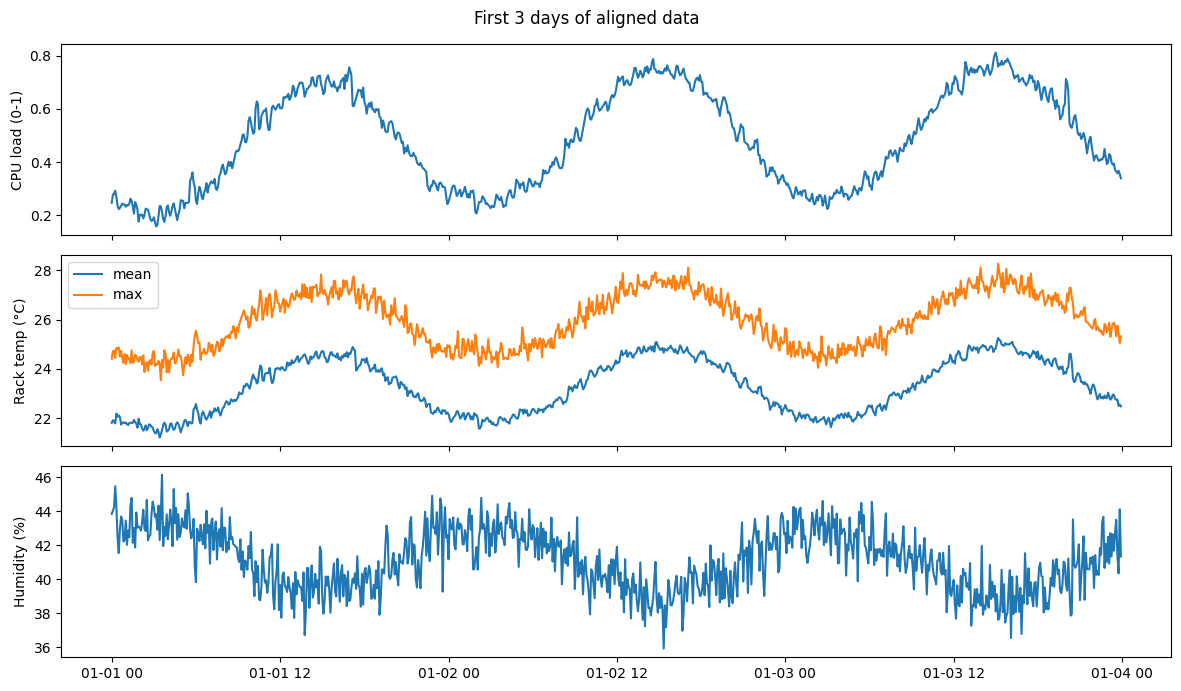

Correlation CPU load vs mean temperature: 0.976


In [5]:
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
d = data.iloc[: 288 * 3]
ax[0].plot(d.index, d["cpu"]);         ax[0].set_ylabel("CPU load (0-1)")
ax[1].plot(d.index, d["temp_mean"], label="mean"); ax[1].plot(d.index, d["temp_max"], label="max")
ax[1].set_ylabel("Rack temp (°C)"); ax[1].legend()
ax[2].plot(d.index, d["hum"]);         ax[2].set_ylabel("Humidity (%)")
plt.suptitle("First 3 days of aligned data"); plt.tight_layout(); plt.show()
print("Correlation CPU load vs mean temperature:", round(data["cpu"].corr(data["temp_mean"]), 3))

## 3. LSTM — CPU load forecasting

windows: (6007, 36, 4) | train/val/test: 4192 907 908
Epoch 1/40
33/33 - 12s - 365ms/step - loss: 0.0764 - val_loss: 0.0040
Epoch 2/40
33/33 - 7s - 200ms/step - loss: 0.0032 - val_loss: 0.0016
Epoch 3/40
33/33 - 3s - 102ms/step - loss: 0.0025 - val_loss: 0.0015
Epoch 4/40
33/33 - 4s - 117ms/step - loss: 0.0024 - val_loss: 0.0015
Epoch 5/40
33/33 - 3s - 84ms/step - loss: 0.0024 - val_loss: 0.0016
Epoch 6/40
33/33 - 3s - 83ms/step - loss: 0.0023 - val_loss: 0.0015
Epoch 7/40
33/33 - 6s - 193ms/step - loss: 0.0023 - val_loss: 0.0015
Epoch 8/40
33/33 - 3s - 100ms/step - loss: 0.0022 - val_loss: 0.0016
Epoch 9/40
33/33 - 3s - 79ms/step - loss: 0.0022 - val_loss: 0.0015
Epoch 10/40
33/33 - 3s - 81ms/step - loss: 0.0022 - val_loss: 0.0015
Epoch 11/40
33/33 - 3s - 78ms/step - loss: 0.0021 - val_loss: 0.0015
Epoch 12/40
33/33 - 5s - 138ms/step - loss: 0.0021 - val_loss: 0.0014
Epoch 13/40
33/33 - 3s - 94ms/step - loss: 0.0021 - val_loss: 0.0014
Epoch 14/40
33/33 - 3s - 76ms/step - loss: 0.0021 

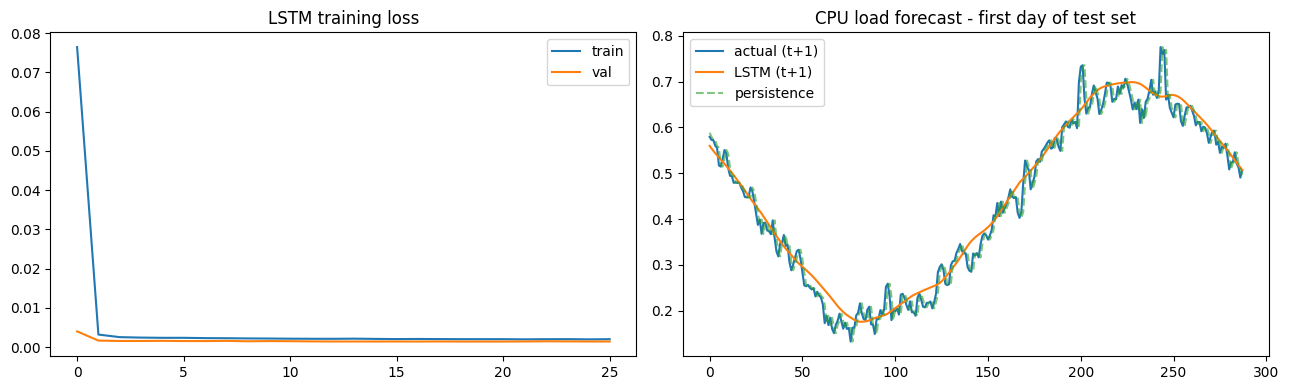

In [15]:
feat = ["cpu", "hour_sin", "hour_cos", "temp_mean"]
cpu_idx = feat.index("cpu")
scaler = MinMaxScaler().fit(data[feat].iloc[:i_tr])
X_all = scaler.transform(data[feat]).astype("float32")
c_min, c_rng = scaler.data_min_[cpu_idx], scaler.data_range_[cpu_idx]
inv_cpu = lambda a: a * c_rng + c_min

# Decision time t: input = [t-LOOKBACK+1 .. t], target = cpu[t+1 .. t+HORIZON]
T_idx = np.arange(LOOKBACK - 1, N - HORIZON)
Xw = np.stack([X_all[t - LOOKBACK + 1: t + 1] for t in T_idx])
yw = np.stack([X_all[t + 1: t + HORIZON + 1, cpu_idx] for t in T_idx])
t_end = T_idx + HORIZON                        # split on the END of the target -> no leakage
tr, va, te = t_end < i_tr, (t_end >= i_tr) & (t_end < i_va), t_end >= i_va
print("windows:", Xw.shape, "| train/val/test:", tr.sum(), va.sum(), te.sum())

lstm = models.Sequential([
    layers.Input(shape=(LOOKBACK, len(feat))),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dense(HORIZON),
])
lstm.compile(optimizer="adam", loss="mse")
hist = lstm.fit(Xw[tr], yw[tr], validation_data=(Xw[va], yw[va]), epochs=40, batch_size=128,
                callbacks=[callbacks.EarlyStopping(patience=5, restore_best_weights=True)], verbose=2)

# ---- Evaluation vs. persistence baseline (last value repeated) ----
pred = inv_cpu(lstm.predict(Xw[te], verbose=0))
true = inv_cpu(yw[te])
naive = np.repeat(inv_cpu(Xw[te][:, -1, cpu_idx])[:, None], HORIZON, axis=1)
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a.ravel(), b.ravel())))
lstm_metrics = {"LSTM_MAE": float(mean_absolute_error(true.ravel(), pred.ravel())), "LSTM_RMSE": rmse(true, pred),
                "Naive_MAE": float(mean_absolute_error(true.ravel(), naive.ravel())), "Naive_RMSE": rmse(true, naive)}
print(json.dumps({k: round(v, 4) for k, v in lstm_metrics.items()}, indent=2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val")
ax[0].set_title("LSTM training loss"); ax[0].legend()
k = min(288, len(true))
ax[1].plot(true[:k, 0], label="actual (t+1)"); ax[1].plot(pred[:k, 0], label="LSTM (t+1)")
ax[1].plot(naive[:k, 0], "--", alpha=.6, label="persistence")
ax[1].set_title("CPU load forecast - first day of test set"); ax[1].legend()
plt.tight_layout(); plt.show()

# ---- Forecast for EVERY time step (needed as an input of the Random Forest) ----
T_inf = np.arange(LOOKBACK - 1, N)
X_inf = np.stack([X_all[t - LOOKBACK + 1: t + 1] for t in T_inf])
pred_vec = np.full((N, HORIZON), np.nan)
pred_vec[T_inf] = inv_cpu(lstm.predict(X_inf, verbose=0))
cpu_pred = pd.Series(pred_vec.mean(axis=1), index=data.index)

## 4. CNN — 2D thermal maps & hotspot detection

Hotspot threshold: 27.06 °C | hotspot rate: 27.0%
CNN input: (6042, 6, 6, 3) | train/val/test: 4221 907 908
Epoch 1/30
33/33 - 12s - 361ms/step - auc: 0.9449 - loss: 0.5258 - val_auc: 0.9858 - val_loss: 0.1575
Epoch 2/30
33/33 - 4s - 116ms/step - auc: 0.9741 - loss: 0.2892 - val_auc: 0.9867 - val_loss: 0.1501
Epoch 3/30
33/33 - 3s - 85ms/step - auc: 0.9773 - loss: 0.2707 - val_auc: 0.9869 - val_loss: 0.1486
Epoch 4/30
33/33 - 3s - 100ms/step - auc: 0.9782 - loss: 0.2640 - val_auc: 0.9867 - val_loss: 0.1438
Epoch 5/30
33/33 - 1s - 44ms/step - auc: 0.9793 - loss: 0.2590 - val_auc: 0.9869 - val_loss: 0.1483
Epoch 6/30
33/33 - 1s - 24ms/step - auc: 0.9799 - loss: 0.2565 - val_auc: 0.9869 - val_loss: 0.1453
Epoch 7/30
33/33 - 1s - 26ms/step - auc: 0.9794 - loss: 0.2562 - val_auc: 0.9869 - val_loss: 0.1441
Epoch 8/30
33/33 - 1s - 36ms/step - auc: 0.9799 - loss: 0.2510 - val_auc: 0.9866 - val_loss: 0.1419
Epoch 9/30
33/33 - 1s - 25ms/step - auc: 0.9806 - loss: 0.2493 - val_auc: 0.9867 - val_l

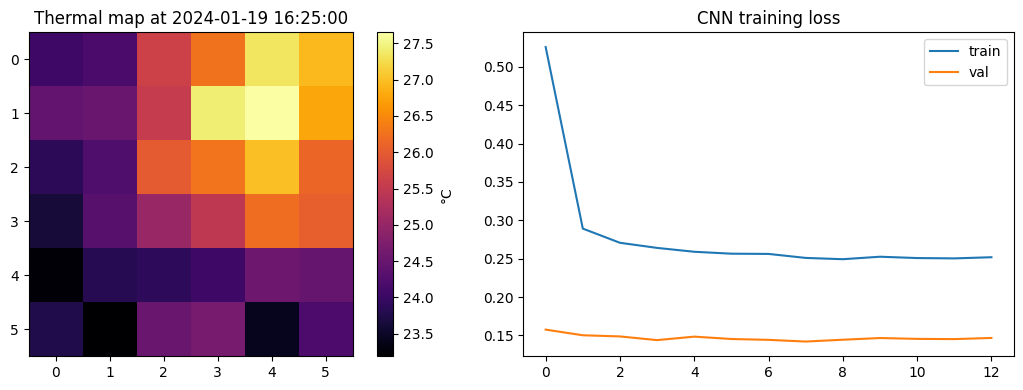

In [18]:
n = len(sensor_cols)
G = max(3, math.ceil(math.sqrt(n)))

def to_grid(values):                           # (t, n) -> (t, G, G); padding = row mean
    pad = G * G - n
    if pad:
        values = np.hstack([values, np.repeat(values.mean(axis=1, keepdims=True), pad, axis=1)])
    return values.reshape(-1, G, G)

grids = to_grid(data[sensor_cols].values).astype("float32")
mu, sd = grids[:i_tr].mean(), grids[:i_tr].std() + 1e-6
grids_n = (grids - mu) / sd

# Hotspot label: will the hottest sensor exceed the threshold within the next HORIZON steps?
thr = float(HOT_THRESHOLD) if HOT_THRESHOLD is not None else float(data["temp_max"].iloc[:i_tr].quantile(HOT_QUANTILE))
fut_max = data["temp_max"][::-1].rolling(HORIZON).max()[::-1].shift(-1)       # max over t+1..t+H
hot_future = (fut_max > thr).astype(float).where(fut_max.notna())
print(f"Hotspot threshold: {thr:.2f} °C | hotspot rate: {np.nanmean(hot_future.values):.1%}")

LAGS = (0, 3, 6)                               # channels = map at t, t-3, t-6
tmin = max(LAGS)
T_cnn = np.arange(tmin, N)
Xc = np.stack([np.stack([grids_n[t - l] for l in LAGS], axis=-1) for t in T_cnn]).astype("float32")
yc = hot_future.values[T_cnn]
ok = ~np.isnan(yc)
tc_end = T_cnn + HORIZON
ctr = ok & (tc_end < i_tr); cva = ok & (tc_end >= i_tr) & (tc_end < i_va); cte = ok & (tc_end >= i_va)
print("CNN input:", Xc.shape, "| train/val/test:", ctr.sum(), cva.sum(), cte.sum())

cnn = models.Sequential([
    layers.Input(shape=(G, G, len(LAGS))),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.GlobalMaxPooling2D(),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
cnn.compile(optimizer="adam", loss="binary_crossentropy", metrics=[tf.keras.metrics.AUC(name="auc")])
pos = float(yc[ctr].mean())
cw = {0: 1.0, 1: float(min(5.0, (1.0 - pos) / max(pos, 1e-3)) if pos > 0 else 1.0)}
hist_c = cnn.fit(Xc[ctr], yc[ctr], validation_data=(Xc[cva], yc[cva]), epochs=30, batch_size=128,
                 class_weight=cw, callbacks=[callbacks.EarlyStopping(patience=5, restore_best_weights=True)],
                 verbose=2)

p_te = cnn.predict(Xc[cte], verbose=0).ravel()
y_te = yc[cte]
cnn_metrics = {"CNN_AUC": float(roc_auc_score(y_te, p_te)) if len(np.unique(y_te)) > 1 else float("nan"),
               "CNN_F1": float(f1_score(y_te, p_te > 0.5))}
cur_hot = (data["temp_max"].values[T_cnn][cte] > thr).astype(float)
cnn_metrics["Persistence_F1"] = float(f1_score(y_te, cur_hot))
print({k: round(v, 3) for k, v in cnn_metrics.items()})
print("Confusion matrix [[TN FP],[FN TP]]:\n", confusion_matrix(y_te, p_te > 0.5))

# ---- Hotspot probability for EVERY time step (input of the Random Forest) ----
hot_prob = pd.Series(np.nan, index=data.index)
hot_prob.iloc[T_cnn] = cnn.predict(Xc, verbose=0).ravel()

# ---- Visual: an example thermal map ----
t_show = int(np.argmax(data["temp_max"].values[i_va:])) + i_va
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(grids[t_show], cmap="inferno"); ax[0].set_title(f"Thermal map at {data.index[t_show]}")
plt.colorbar(im, ax=ax[0], label="°C")
ax[1].plot(hist_c.history["loss"], label="train"); ax[1].plot(hist_c.history["val_loss"], label="val")
ax[1].set_title("CNN training loss"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Random Forest — dynamic HVAC control

> ⚠️ **Important assumption.** The public datasets contain no record of actual HVAC actions, so there is no real "setpoint" label.
> The Random Forest is trained to imitate an **oracle control policy** computed with *future* information
> (the highest safe setpoint given the true temperatures of the next 30 min). At run time it only sees information available *now*
> (LSTM forecast + CNN hotspot probability + sensors). This is a standard approach when logs of control actions are missing — say so in the report.

{'RF_MAE_degC': 0.296, 'RF_R2': 0.955}


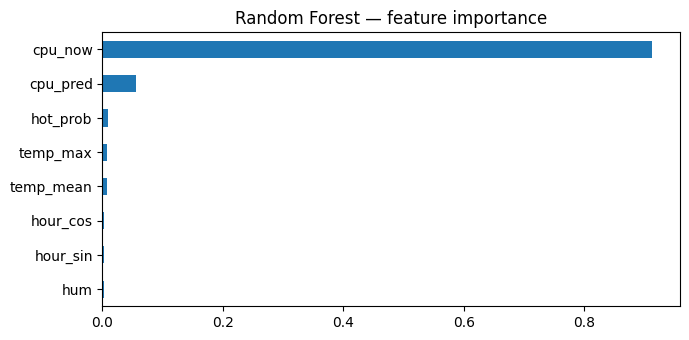

In [17]:
# Oracle policy: highest safe setpoint given future information
worst_temp = np.maximum(fut_max, data["temp_max"])
sp_oracle = (BASE_SETPOINT + (thr - SAFETY_MARGIN - worst_temp) / K_PASS).clip(SP_MIN, SP_MAX)

rf_feats = ["cpu_now", "cpu_pred", "hot_prob", "temp_mean", "temp_max", "hum", "hour_sin", "hour_cos"]
F = pd.DataFrame({"cpu_now": data["cpu"], "cpu_pred": cpu_pred, "hot_prob": hot_prob,
                  "temp_mean": data["temp_mean"], "temp_max": data["temp_max"], "hum": data["hum"],
                  "hour_sin": data["hour_sin"], "hour_cos": data["hour_cos"]})
F["target"] = sp_oracle
F = F.dropna()
pos_t = data.index.get_indexer(F.index)
rtr = pos_t + HORIZON < i_tr
rte = pos_t >= i_va

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
rf.fit(F.loc[rtr, rf_feats], F.loc[rtr, "target"])
rf_pred = rf.predict(F.loc[rte, rf_feats])
rf_metrics = {"RF_MAE_degC": float(mean_absolute_error(F.loc[rte, "target"], rf_pred)),
              "RF_R2": float(r2_score(F.loc[rte, "target"], rf_pred))}
print({k: round(v, 3) for k, v in rf_metrics.items()})

imp = pd.Series(rf.feature_importances_, index=rf_feats).sort_values()
imp.plot.barh(figsize=(7, 3.5), title="Random Forest — feature importance"); plt.tight_layout(); plt.show()

def decide_setpoint(row_feats, safety=True):
    """Control law used online: RF prediction + safety layer based on CNN hotspot risk."""
    sp = float(rf.predict(pd.DataFrame([row_feats])[rf_feats])[0])
    if safety and row_feats["hot_prob"] > 0.8:
        sp = min(sp, BASE_SETPOINT - 2.0)
    return float(np.clip(sp, SP_MIN, SP_MAX))

## 6. Energy, cost & carbon evaluation (test period)

{
  "cooling_kWh_baseline": 855.1,
  "cooling_kWh_AI": 824.6,
  "energy_saved_kWh": 30.5,
  "energy_saved_pct": 3.57,
  "CO2_avoided_kg": 13.7,
  "cost_saved": 3.05,
  "PUE_baseline": 1.313,
  "PUE_AI": 1.293,
  "time_above_hot_threshold_baseline_pct": 7.43,
  "time_above_hot_threshold_AI_pct": 0.22,
  "test_days": 3.1
}


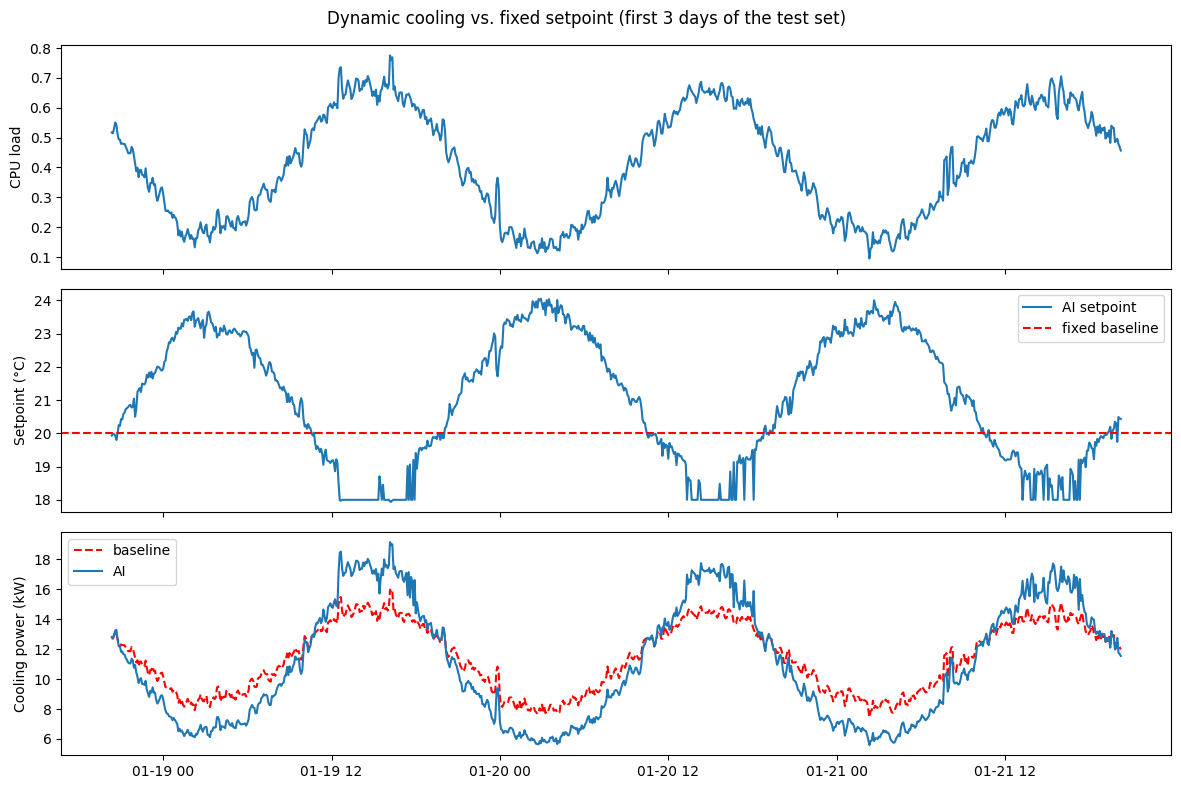

In [9]:
def cop(T):                                    # CRAC coefficient of performance vs supply temperature
    return 0.0068 * T ** 2 + 0.0008 * T + 0.458

dt_h = pd.Timedelta(STEP).total_seconds() / 3600
Te = F.loc[rte].copy()
sp_dyn = rf.predict(Te[rf_feats])
sp_dyn = np.where(Te["hot_prob"].values > 0.8, np.minimum(sp_dyn, BASE_SETPOINT - 2.0), sp_dyn)
sp_dyn = np.clip(sp_dyn, SP_MIN, SP_MAX)

p_it = N_SERVERS * (P_IDLE_KW + (P_MAX_KW - P_IDLE_KW) * Te["cpu_now"].values)          # kW
cool_base = p_it / cop(BASE_SETPOINT)
cool_dyn = p_it / cop(sp_dyn)

kwh_base, kwh_dyn = cool_base.sum() * dt_h, cool_dyn.sum() * dt_h
saved = kwh_base - kwh_dyn
pue_base = float(((p_it + cool_base) / p_it).mean())
pue_dyn = float(((p_it + cool_dyn) / p_it).mean())

# Thermal safety (simple model; the observed data is assumed to be the baseline policy)
tmax_dyn = Te["temp_max"].values + K_PASS * (sp_dyn - BASE_SETPOINT)
viol_base = float((Te["temp_max"].values > thr).mean())
viol_dyn = float((tmax_dyn > thr).mean())

results = {
    "cooling_kWh_baseline": round(kwh_base, 1), "cooling_kWh_AI": round(kwh_dyn, 1),
    "energy_saved_kWh": round(saved, 1), "energy_saved_pct": round(100 * saved / kwh_base, 2),
    "CO2_avoided_kg": round(saved * CO2_KG_PER_KWH, 1), "cost_saved": round(saved * PRICE_PER_KWH, 2),
    "PUE_baseline": round(pue_base, 3), "PUE_AI": round(pue_dyn, 3),
    "time_above_hot_threshold_baseline_pct": round(100 * viol_base, 2),
    "time_above_hot_threshold_AI_pct": round(100 * viol_dyn, 2),
    "test_days": round(len(Te) * dt_h / 24, 1),
}
print(json.dumps(results, indent=2))

fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
k = min(288 * 3, len(Te)); ix = Te.index[:k]
ax[0].plot(ix, Te["cpu_now"].values[:k]); ax[0].set_ylabel("CPU load")
ax[1].plot(ix, sp_dyn[:k], label="AI setpoint"); ax[1].axhline(BASE_SETPOINT, color="r", ls="--", label="fixed baseline")
ax[1].set_ylabel("Setpoint (°C)"); ax[1].legend()
ax[2].plot(ix, cool_base[:k], "r--", label="baseline"); ax[2].plot(ix, cool_dyn[:k], label="AI")
ax[2].set_ylabel("Cooling power (kW)"); ax[2].legend()
plt.suptitle("Dynamic cooling vs. fixed setpoint (first 3 days of the test set)"); plt.tight_layout(); plt.show()

## 7. Demo — one decision step & saving the deliverables

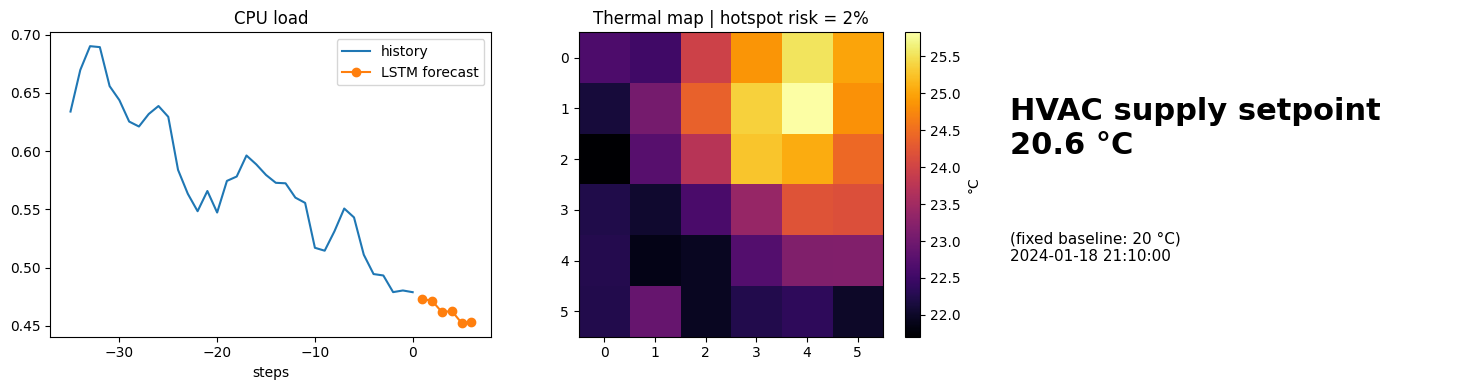

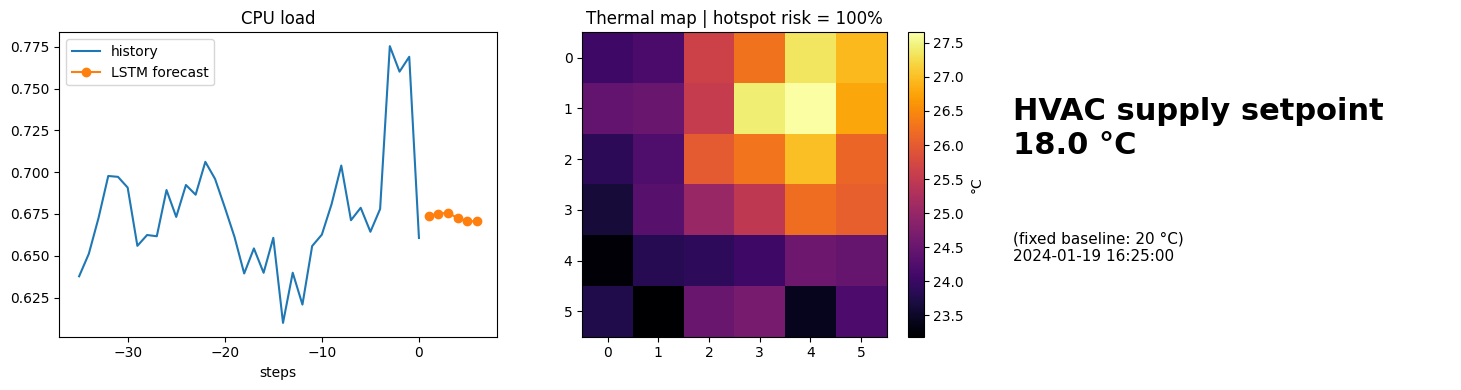

Saved to ./outputs -> ['rf_hvac_controller.joblib', 'lstm_cpu_forecast.keras', 'test_control_log.csv', 'metrics.json', 'cnn_hotspot.keras']


In [10]:
def demo(position):
    """Show what the system does at one time step: forecast -> thermal map -> HVAC decision."""
    ts = F.index[position]; row = F.loc[ts, rf_feats].to_dict()
    t = data.index.get_loc(ts)
    sp = decide_setpoint(row)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].plot(range(-LOOKBACK + 1, 1), data["cpu"].values[t - LOOKBACK + 1: t + 1], label="history")
    ax[0].plot(range(1, HORIZON + 1), pred_vec[t], "o-", label="LSTM forecast")
    ax[0].set_title("CPU load"); ax[0].set_xlabel("steps"); ax[0].legend()
    im = ax[1].imshow(grids[t], cmap="inferno"); plt.colorbar(im, ax=ax[1], label="°C")
    ax[1].set_title(f"Thermal map | hotspot risk = {row['hot_prob']:.0%}")
    ax[2].axis("off")
    ax[2].text(0, .6, f"HVAC supply setpoint\n{sp:.1f} °C", fontsize=22, weight="bold")
    ax[2].text(0, .25, f"(fixed baseline: {BASE_SETPOINT:.0f} °C)\n{ts}", fontsize=11)
    plt.tight_layout(); plt.show()

demo(int(np.where(rte)[0][10]))                          # a calm moment
demo(int(np.where(rte)[0][np.argmax(Te["hot_prob"].values)]))   # highest hotspot risk

# ---- Save everything ----
lstm.save(f"{OUT}/lstm_cpu_forecast.keras")
cnn.save(f"{OUT}/cnn_hotspot.keras")
import joblib; joblib.dump(rf, f"{OUT}/rf_hvac_controller.joblib", compress=3)
all_metrics = {**lstm_metrics, **cnn_metrics, **rf_metrics, **results, "synthetic_data": USING_SYNTHETIC}
json.dump(all_metrics, open(f"{OUT}/metrics.json", "w"), indent=2)
pd.DataFrame({
    **{column: Te[column].values for column in rf_feats},
    "cpu_load": Te["cpu_now"].values, "setpoint_AI": sp_dyn,
    "cooling_kW_baseline": cool_base, "cooling_kW_AI": cool_dyn,
}, index=Te.index).to_csv(f"{OUT}/test_control_log.csv")
print("Saved to", OUT, "->", os.listdir(OUT))

## 7b. Export everything as ONE installable `.mpk` package

The three trained models (LSTM, CNN, Random Forest) and everything needed to run them — scaler values, hotspot threshold,
thermal-map layout, feature lists, energy assumptions, metrics and a 7-day replay sample — are bundled into a single
**`.mpk`** file (MessagePack). The CLI and the Streamlit app load this file; no retraining and no notebook needed.

**Workflow:** train here (Kaggle GPU or locally) → download `datacenter_cooling_models.mpk` → put it in the project's `models/` folder → `streamlit run app/streamlit_app.py`.

> ⚠️ The Random Forest is stored with `joblib` (pickle). Only install `.mpk` files from sources you trust.

In [13]:
# Install and import msgpack silently to ensure the export works seamlessly
!pip install -q msgpack
import msgpack

MPK_FORMAT   = "datacenter-cooling-models"
MPK_PATH     = f"{MODELS_DIR}/datacenter_cooling_models.mpk"
MODEL_FILES  = ["lstm_cpu_forecast.keras", "cnn_hotspot.keras", "rf_hvac_controller.joblib"]
REPLAY_STEPS = 7 * 288          # 7 days of the test period shipped inside the package (for demos)

def build_mpk(path=MPK_PATH):
    meta = {
        "step": STEP, "lookback": LOOKBACK, "horizon": HORIZON,
        "lstm_features": feat, "rf_features": rf_feats,
        "scaler_data_min": scaler.data_min_.tolist(), "scaler_data_range": scaler.data_range_.tolist(),
        "grid_side": int(G), "n_sensors": int(n), "sensor_cols": sensor_cols, "cnn_lags": list(LAGS),
        "cnn_norm_mean": float(mu), "cnn_norm_std": float(sd),
        "hot_threshold_C": float(thr), "hot_prob_safety_limit": 0.8,
        "base_setpoint_C": BASE_SETPOINT, "setpoint_range_C": [SP_MIN, SP_MAX],
        "energy": {"n_servers": N_SERVERS, "p_idle_kw": P_IDLE_KW, "p_max_kw": P_MAX_KW, "k_pass": K_PASS,
                   "safety_margin": SAFETY_MARGIN, "co2_kg_per_kwh": CO2_KG_PER_KWH, "price_per_kwh": PRICE_PER_KWH},
        "synthetic_data": bool(USING_SYNTHETIC),
        "metrics": all_metrics,
    }
    meta = json.loads(json.dumps(meta, default=float))        # plain JSON types only (no numpy)
    files = {}
    for name in MODEL_FILES:
        with open(f"{OUT}/{name}", "rb") as f:
            files[name] = f.read()
    start = max(0, i_va - 48)                                   # 48 warm-up steps before the test period
    replay = data[sensor_cols + ["cpu", "hum"]].iloc[start: start + 48 + REPLAY_STEPS]
    files["demo_replay.csv"] = replay.round(4).to_csv(index_label="time").encode()
    bundle = {"format": MPK_FORMAT, "version": 1, "meta": meta, "files": files}
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "wb") as f:
        f.write(msgpack.packb(bundle, use_bin_type=True))
    print(f"Created {os.path.abspath(path)}  ({os.path.getsize(path) / 1e6:.2f} MB, {len(MODEL_FILES)} models + replay sample)")
    return path

build_mpk()

Created /content/outputs/datacenter_cooling_models.mpk  (7.35 MB, 3 models + replay sample)


'./outputs/datacenter_cooling_models.mpk'

In [12]:
# ---- INSTALL: restore the models from a .mpk file (fresh notebook / another machine) ----
# (the project's `cooling_ai.CoolingEngine.from_mpk(...)` does the same thing for the CLI and the app)
def install_mpk(path, dest="./installed_models", load=True):
    """Unpack a .mpk bundle into `dest` and (optionally) load the models.
    Returns {"lstm": ..., "cnn": ..., "rf": ..., "meta": {...}}."""
    import joblib
    with open(path, "rb") as f:
        bundle = msgpack.unpackb(f.read(), raw=False)
    if bundle.get("format") != MPK_FORMAT:
        raise ValueError(f"{path} is not a '{MPK_FORMAT}' package")
    os.makedirs(dest, exist_ok=True)
    for name, blob in bundle["files"].items():
        with open(os.path.join(dest, os.path.basename(name)), "wb") as f:   # basename = no path traversal
            f.write(blob)
    json.dump(bundle["meta"], open(os.path.join(dest, "meta.json"), "w"), indent=2)
    print(f"Installed {len(bundle['files'])} files into {os.path.abspath(dest)}")
    if not load:
        return {"meta": bundle["meta"], "dir": dest}
    return {
        "lstm": models.load_model(os.path.join(dest, "lstm_cpu_forecast.keras")),
        "cnn":  models.load_model(os.path.join(dest, "cnn_hotspot.keras")),
        "rf":   joblib.load(os.path.join(dest, "rf_hvac_controller.joblib")),
        "meta": bundle["meta"],
    }

# Self-test: install the package we just built and check it reproduces the Random Forest output
pkg = install_mpk(MPK_PATH, dest=f"{OUT}/installed_models")
check = pkg["rf"].predict(F.loc[rte, rf_feats].iloc[:5])
print("Installed RF matches original:", bool(np.allclose(check, rf.predict(F.loc[rte, rf_feats].iloc[:5]))))
print("Hotspot threshold stored in package:", round(pkg["meta"]["hot_threshold_C"], 2), "°C")
print("\nNext step -> copy the .mpk into the project's models/ folder and run:  streamlit run app/streamlit_app.py")

Installed 4 files into /content/outputs/installed_models
Installed RF matches original: True
Hotspot threshold stored in package: 27.06 °C

Next step -> copy the .mpk into the project's models/ folder and run:  streamlit run app/streamlit_app.py


In [14]:
# Execute this cell to download the compiled .mpk file directly to your PC
from google.colab import files
try:
    files.download(MPK_PATH)
    print("Triggered browser download for:", MPK_PATH)
except Exception as e:
    print("Download failed:", e)
    print("You can manually download the file from the left folder sidebar in Google Colab (inside outputs/datacenter_cooling_models.mpk).")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggered browser download for: ./outputs/datacenter_cooling_models.mpk


## 8. Notes for the technical report
- **Assumptions to state:** time alignment of the two datasets, sensor-to-grid layout, oracle setpoint policy, energy model (server power, CRAC COP curve, K_PASS, emission factor, price).
- **Honest limits:** RF/CNN are partly evaluated in-sample for the RF training period; savings come from a model, not from a real data center; with real data, validate on a held-out period and with physical measurements.
- **Possible extensions:** multi-step LSTM with attention, real rack coordinates for the CNN, reinforcement learning for the controller, a Streamlit/Gradio front-end for the demo.